In [1]:
from pyspark.sql import SparkSession
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import DecisionTreeRegressor
from pyspark.ml.evaluation import RegressionEvaluator
import mlflow
import mlflow.spark

# Spark Oturumunu Baslat (Delta destegi ile)
spark = SparkSession.builder \
    .appName("NYC-Taxi-ModelTraining-DT") \
    .config("spark.jars.packages", "io.delta:delta-spark_2.12:3.1.0") \
    .config("spark.sql.extensions", "io.delta.sql.DeltaSparkSessionExtension") \
    .config("spark.sql.catalog.spark_catalog", "org.apache.spark.sql.delta.catalog.DeltaCatalog") \
    .getOrCreate()

# MLflow Ayarlari
mlflow.set_tracking_uri("http://mlflow-server:5001")
mlflow.set_experiment("Taxi_Fare_Prediction")

print("Spark ve MLflow Hazir.")

Spark ve MLflow Hazir.


In [2]:
# Adim 5'te kaydettigimiz Gold tablosunu yukluyoruz.
gold_path = "/home/jovyan/work/data/delta/features"
df = spark.read.format("delta").load(gold_path)

print(f"Egitim icin yuklenen toplam kayit sayisi: {df.count()}")
df.printSchema()

Egitim icin yuklenen toplam kayit sayisi: 1798960
root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)
 |-- trip_duration_min: double (nullable = true)
 |-- average_speed: double 

In [3]:
# Modelde kullanilacak ozellikler
feature_cols = [
    "trip_distance", 
    "trip_duration_min", 
    "average_speed", 
    "pickup_hour", 
    "day_of_week", 
    "is_airport_trip", 
    "is_rush_hour"
]

assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
final_df = assembler.transform(df).select("features", "total_amount")

# Veriyi %80 Egitim, %20 Dogrulama olarak ayiriyoruz
train_df, validation_df = final_df.randomSplit([0.8, 0.2], seed=42)

print(f"Egitim seti: {train_df.count()} kayit")
print(f"Dogrulama seti: {validation_df.count()} kayit")

Egitim seti: 1439385 kayit
Dogrulama seti: 359575 kayit


In [4]:
with mlflow.start_run(run_name="Decision_Tree_Final"):
    # 1. Model Parametreleri
    max_depth = 5
    
    dt = DecisionTreeRegressor(
        featuresCol="features",
        labelCol="total_amount",
        maxDepth=max_depth
    )
    
    # 2. Modeli Egit
    print("Decision Tree Modeli egitiliyor, lutfen bekleyin...")
    dt_model = dt.fit(train_df)
    
    # 3. Tahmin Yap
    predictions = dt_model.transform(validation_df)
    
    # 4. Metrikleri Hesapla
    evaluator_rmse = RegressionEvaluator(labelCol="total_amount", predictionCol="prediction", metricName="rmse")
    evaluator_mae = RegressionEvaluator(labelCol="total_amount", predictionCol="prediction", metricName="mae")
    evaluator_r2 = RegressionEvaluator(labelCol="total_amount", predictionCol="prediction", metricName="r2")
    
    rmse = evaluator_rmse.evaluate(predictions)
    mae = evaluator_mae.evaluate(predictions)
    r2 = evaluator_r2.evaluate(predictions)
    
    # 5. MLflow'a Logla
    mlflow.log_param("model_type", "DecisionTreeRegressor")
    mlflow.log_param("maxDepth", max_depth)
    mlflow.log_metric("rmse", rmse)
    mlflow.log_metric("mae", mae)
    mlflow.log_metric("r2", r2)
    
    mlflow.spark.log_model(dt_model, "dt_model")
    
    print(f"Model Basariyla Egitildi.")
    print(f"RMSE: {rmse:.2f}")
    print(f"MAE: {mae:.2f}")
    print(f"R2 Score: {r2:.2f}")

Decision Tree Modeli egitiliyor, lutfen bekleyin...
Model Basariyla Egitildi.
RMSE: 7.36
MAE: 3.47
R2 Score: 0.89
🏃 View run Decision_Tree_Final at: http://mlflow-server:5001/#/experiments/1/runs/823e26eea47445139a08317c04bb3188
🧪 View experiment at: http://mlflow-server:5001/#/experiments/1


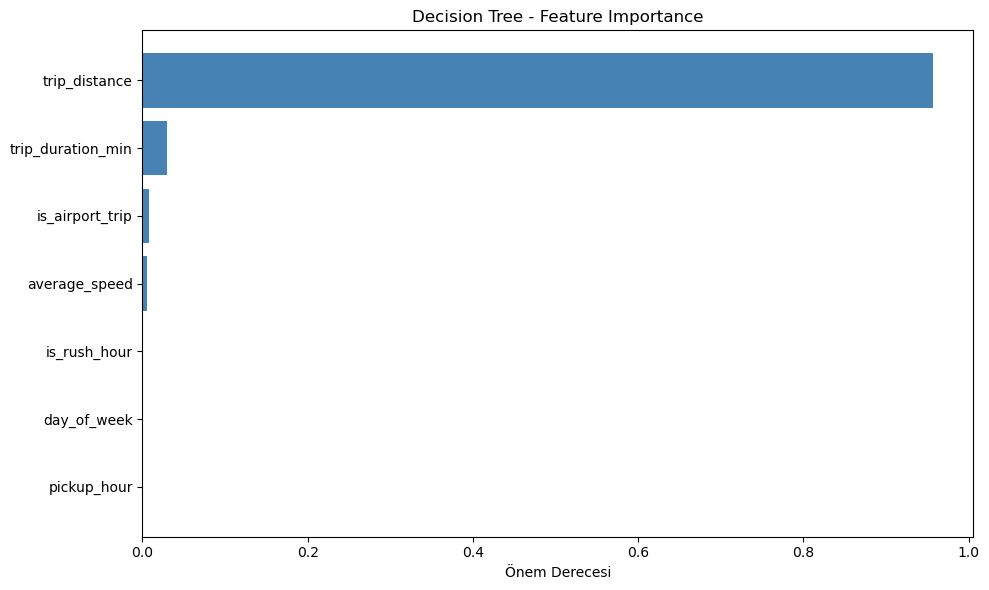

✅ Feature importance grafiği kaydedildi.


In [5]:
import matplotlib.pyplot as plt
import pandas as pd

# Feature importance
feature_importances = dt_model.featureImportances
importance_list = [(feature_cols[i], float(feature_importances[i])) for i in range(len(feature_cols))]
importance_df = pd.DataFrame(importance_list, columns=["Feature", "Importance"])
importance_df = importance_df.sort_values("Importance", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(importance_df["Feature"], importance_df["Importance"], color="steelblue")
plt.title("Decision Tree - Feature Importance")
plt.xlabel("Önem Derecesi")
plt.tight_layout()
plt.savefig("/home/jovyan/work/data/dt_feature_importance.png")
plt.show()
print("✅ Feature importance grafiği kaydedildi.")

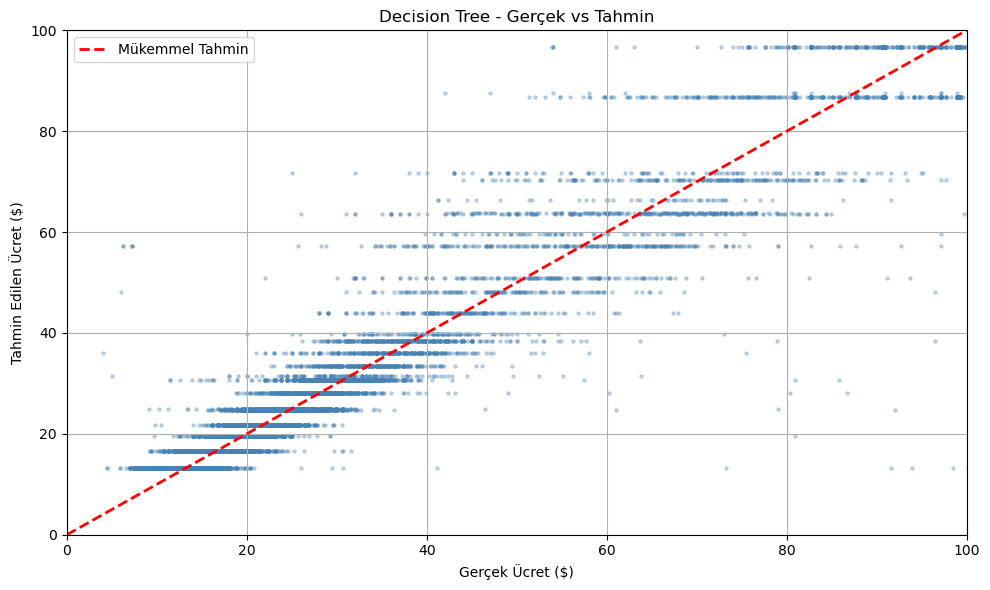

✅ Scatter plot kaydedildi.


In [6]:
# Gerçek vs Tahmin scatter plot
sample = predictions.select("total_amount", "prediction") \
    .sample(fraction=0.05) \
    .toPandas()

plt.figure(figsize=(10, 6))
plt.scatter(sample["total_amount"], sample["prediction"], alpha=0.3, s=5, color="steelblue")
plt.plot([0, 100], [0, 100], color="red", linewidth=2, linestyle="--", label="Mükemmel Tahmin")
plt.title("Decision Tree - Gerçek vs Tahmin")
plt.xlabel("Gerçek Ücret ($)")
plt.ylabel("Tahmin Edilen Ücret ($)")
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/home/jovyan/work/data/dt_actual_vs_predicted.png")
plt.show()
print("✅ Scatter plot kaydedildi.")